# Функции
### От `def` к областям видимости

# Функции и аргументы
## Назначение функций
Функция — это способ **упаковать набор действий** под одним именем и вызывать его многократно. На занятии по управляющим конструкциям мы уже видели основы (`def`, `return`). В этом ноутбуке разберём функции подробнее: аргументы, области видимости и практические приёмы.

Функция — это **именованный блок кода**, который:

- принимает **входные данные** (аргументы);
- выполняет действия;
- может **вернуть результат** (`return`).

**Зачем нужны функции:**
- не повторять один и тот же код (принцип DRY — *Don't Repeat Yourself*);
- делать программу читаемой;
- упростить тестирование и отладку;
- переиспользовать логику в разных местах.

Вы уже знакомы **встроенными функциями** Python: `print()`, `len()`, `sum()`, `max()`, `sorted()`. Собственные функции работают по тому же принципу, но мы сами задаём их поведение.

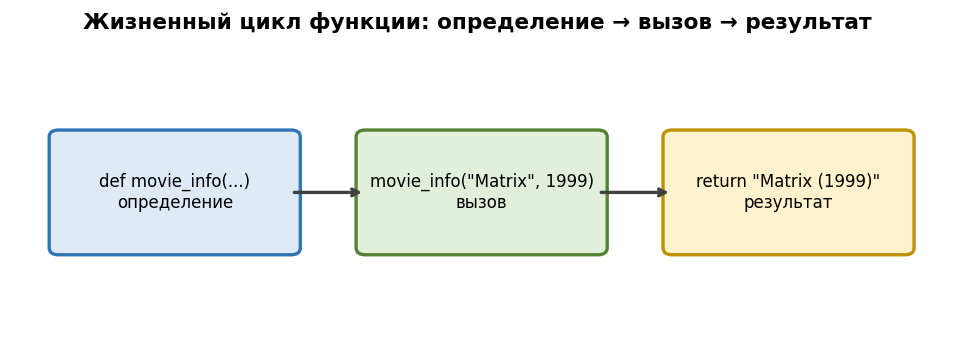

Схема работы:

1. **Определяем** функцию через `def`.
2. **Вызываем** её с нужными аргументами.
3. **Получаем** результат через `return` (или `None`, если `return` нет).



---


## Жизненный цикл функции: `def`, вызов, `return`

Повторим основы написания простых функций.

Без функции приходится повторять один и тот же код:

In [2]:
print("Привет, Анна")
print("Привет, Иван")
print("Привет, Мария")

Привет, Анна
Привет, Иван
Привет, Мария


С функцией — одна логика, разные вызовы:

In [3]:
def greet(name):
    print("Привет,", name)


greet("Анна")
greet("Иван")
greet("Мария")

Привет, Анна
Привет, Иван
Привет, Мария


### Как устроена функция

```text
def имя_функции(аргументы):
    тело функции
```

Функция **не выполняется**, пока мы её не вызовем.

In [4]:
def say_hello():
    print("Привет!")


say_hello()

Привет!


### `return` возвращает результат

Если результат нужно **сохранить и использовать дальше**, используйте `return`, а не `print`.

In [5]:
def add(a, b):
    return a + b


result = add(10, 5)
result

15

**Важно:** `print` и `return` — не одно и то же.

In [6]:
def add_print(a, b):
    print(a + b)


x = add_print(2, 3)
print("x =", x)

5
x = None


`print()` выводит на экран, но **не возвращает** значение — в `x` окажется `None`.

In [7]:
def add_return(a, b):
    return a + b


x = add_return(2, 3)
print("x =", x)
print("x * 10 =", x * 10)

x = 5
x * 10 = 50




---


## Подробнее о функциях

### Docstring — документация функции

Строка в тройных кавычках сразу после `def` объясняет, **что делает** функция. Это называется **docstring**.

In [8]:
def movie_info(title, year):
    """Возвращает краткое описание фильма."""
    return f"{title} ({year})"


movie_info.__doc__

'Возвращает краткое описание фильма.'

### Неявный `return None`

Если в функции нет `return`, Python возвращает `None`.

In [9]:
def show_title(title):
    print(title)


result = show_title("Matrix")
print("result =", result)

Matrix
result = None


### Несколько возвращаемых значений

Функция может вернуть несколько значений — фактически это **кортеж**.

In [10]:
def get_movie_data():
    return "Inception", 2010, 8.8


title, year, rating = get_movie_data()
title, year, rating

('Inception', 2010, 8.8)

### Ранний `return`

Можно выйти из функции раньше, если условие не выполнено.

In [11]:
def safe_rating(value):
    if value < 0 or value > 10:
        return
    return value


safe_rating(8.8), safe_rating(-1)

(8.8, None)

### Функция как «чёрный ящик»

Снаружи важны **вход** и **выход**. Внутренняя реализация может меняться, если результат тот же.

In [12]:
def format_movie(title, year):
    return f"{title} ({year})"


len(format_movie("Matrix", 1999))

13

В хорошем коде встречаются **аннотации типов** (`title: str`), но для начала достаточно понимать логику: аргументы → тело → `return`.



---


## Аргументы в функциях

**Аргументы** — это входные данные функции. Способ передачи влияет на читаемость и гибкость кода.

### Позиционные аргументы

Передаются **по порядку**.

In [13]:
def describe_movie(title, year):
    return f"{title} ({year})"


describe_movie("Inception", 2010)

'Inception (2010)'

Порядок важен. Если перепутать порядок, смысл результата изменится:

In [14]:
describe_movie(2010, "Inception")

'2010 (Inception)'

### Именованные аргументы

Передаются **по имени** — код читается понятнее, порядок можно менять.

In [15]:
describe_movie(title="Inception", year=2010)
describe_movie(year=2010, title="Inception")

'Inception (2010)'

### Аргументы по умолчанию

Можно задать значение, которое используется, если аргумент не передан.

In [16]:
def greet_user(name="Гость"):
    return f"Привет, {name}!"


greet_user(), greet_user("Анна")

('Привет, Гость!', 'Привет, Анна!')

### Правила порядка аргументов

| Правило | Пример |
|---------|--------|
| Сначала позиционные, потом именованные | `fn(10, b=5)` |
| Аргументы с default — в конце сигнатуры | `def fn(a, b=0)` |
| После именованного аргумента нельзя передать позиционный | `fn(a=1, 2)` — ошибка |

### `*args` — переменное число позиционных аргументов

`*args` собирает «лишние» позиционные аргументы в **кортеж**.

In [17]:
def average_rating(*ratings):
    return sum(ratings) / len(ratings)


average_rating(5, 4, 5, 3, 4)

4.2

Удобно, когда заранее неизвестно, сколько значений передадут в функцию.

### `**kwargs` — переменное число именованных аргументов

`**kwargs` собирает именованные аргументы в **словарь**.

In [18]:
def movie_card(**info):
    return info


movie_card(title="Matrix", year=1999, rating=8.7)

{'title': 'Matrix', 'year': 1999, 'rating': 8.7}

`**kwargs` часто встречается в библиотеках, например, pandas, matplotlib, где у функций много настроек.

### Распаковка при вызове

При вызове можно распаковать список или словарь в аргументы.

In [19]:
scores = [5, 4, 5, 3, 4]
average_rating(*scores)

4.2

In [20]:
meta = {"title": "Matrix", "year": 1999, "rating": 8.7}
movie_card(**meta)

{'title': 'Matrix', 'year': 1999, 'rating': 8.7}



---


# 2. Области видимости. Практика
## LEGB, `global`, `nonlocal`

Не каждая переменная «видна» в любом месте программы. **Область видимости** — это участок кода, где имя переменной доступно.

Python ищет имя по правилу **LEGB** (снизу вверх):

1. **L**ocal — локальные переменные внутри функции.
2. **E**nclosing — переменные внешней (объемлющей) функции.
3. **G**lobal — переменные на уровне модуля / ноутбука.
4. **B**uilt-in — встроенные имена (`len`, `print`, `sum`).

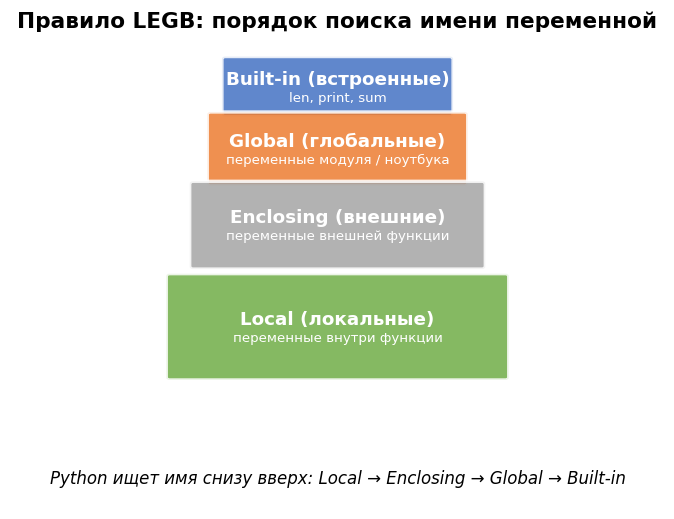

### Local — локальные переменные

In [21]:
title = "Matrix"  # Глобальная переменная


def show_title():
    title = "Inception"  # Локальная переменная
    print("внутри функции:", title)


show_title()
print("снаружи:", title)

внутри функции: Inception
снаружи: Matrix


Присваивание внутри функции создаёт **локальную** переменную — глобальная не меняется.

### Чтение глобальной переменной

Читать глобальную переменную **можно**, если внутри функции её не присваивают.

In [22]:
default_year = 2000


def movie_with_default_year(title):
    return f"{title} ({default_year})"


movie_with_default_year("Avatar")

'Avatar (2000)'

### Enclosing и `nonlocal`

Во **вложенной** функции можно изменить переменную **внешней** функции через `nonlocal`.

In [23]:
def outer():
    genre = "Sci-Fi"

    def inner():
        nonlocal genre
        genre = "Action"

    inner()
    return genre


outer()

'Action'

### `global` — изменение глобальной переменной

Используйте **редко и осознанно**, когда действительно нужно менять глобальное состояние.

In [24]:
views_count = 0


def register_view():
    global views_count
    views_count += 1


register_view()
register_view()
views_count

2

### Built-in — встроенные переменные

`len`, `sum`, `print` и другие — на самом внешнем уровне. Не переопределяйте их без необходимости.

In [25]:
len([1, 2, 3])

3

**Типичная ошибка:**

Разработчик пишет `x = x + 1` внутри функции, подразумевая, что меняется внешняя переменная. Но в таком случае Python создаёт **локальную** переменную `x` и выдаёт ошибку до присваивания.

**Важно:** для изменения внешней переменной нужны `global` или `nonlocal`.



---


## Передача объектов в функции

При вызове функции аргументы передаются как **ссылки на объекты**.

Поведение зависит от того, **изменяемый** объект или **нет**.

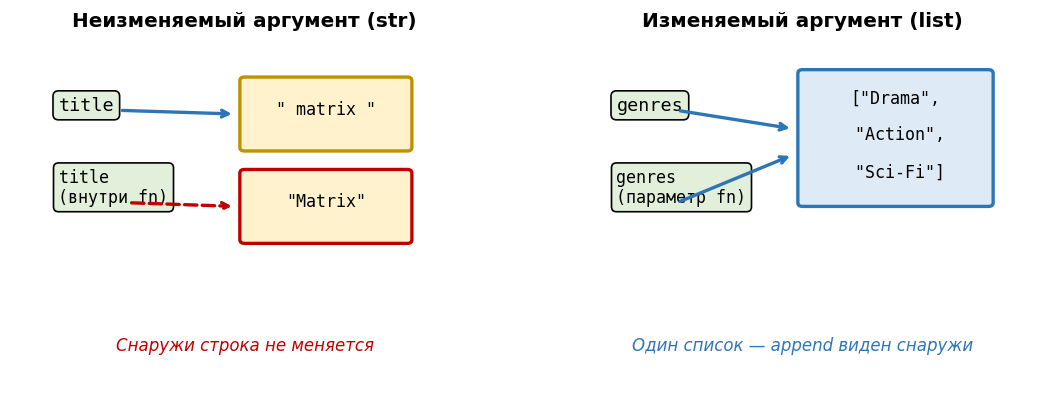

### Изменяемый аргумент — список

Если внутри функции меняется список, изменения видны снаружи.

In [26]:
def add_genre(genres, genre):
    genres.append(genre)


favorite_genres = ["Drama", "Action"]
add_genre(favorite_genres, "Sci-Fi")
favorite_genres

['Drama', 'Action', 'Sci-Fi']

### Неизменяемый аргумент — строка

Строку нельзя изменить «на месте» — снаружи она останется прежней.

In [27]:
def normalize_title(title):
    title = title.strip().title()
    return title


raw = "  matrix  "
result = normalize_title(raw)
raw, result

('  matrix  ', 'Matrix')

### Ловушка: изменяемый аргумент по умолчанию

**Никогда** не используйте изменяемый объект (`list`, `dict`) как значение по умолчанию.

In [28]:
# Некорректно: один и тот же список на всех вызовах:
# def add_movie(movie, catalog=[]):
#     catalog.append(movie)
#     return catalog

# Лучшая практика:
def add_movie(movie, catalog=None):
    if not catalog:
        catalog = []
    catalog.append(movie)
    return catalog


add_movie("Matrix"), add_movie("Inception")

(['Matrix'], ['Inception'])



---


## Lambda-функции

**Lambda** — способ записать **короткую** анонимную функцию в одну строку.

Синтаксис: `lambda аргументы: выражение`

In [29]:
movies = ["Inception", "Matrix", "Avatar"]
sorted(movies, key=lambda name: len(name))

['Matrix', 'Avatar', 'Inception']

Часто lambda передают в `sorted`, `filter`, `map`:

In [30]:
ratings = [5, 3, 4, 5, 2]
list(filter(lambda r: r >= 4, ratings))

[5, 4, 5]

**Когда использовать lambda:** короткая операция «на месте», логика очевидна.

**Когда лучше `def`:** сложная логика, нужен docstring, функцию вызывают из нескольких мест.



---


## Практика

### Мини-аналитика фильмов через функции

Соберём набор функций для обработки данных о фильмах.

### Парсинг жанров из строки

In [31]:
def parse_genres(genres_string): ...


parse_genres("Drama|Action|Sci-Fi")

### Средний рейтинг

In [32]:
def average_rating(ratings): ...


average_rating([5, 4, 5, 3, 4])

### Фильтрация словаря рейтингов

In [33]:
def filter_high_rated(movies_dict, threshold=8.0): ...


filter_high_rated({"Inception": 8.8, "Matrix": 8.7, "Avatar": 7.8})

### Сводка по одному фильму

In [34]:
def movie_summary(title, year, ratings): ...


movie_summary("Inception", 2010, [5, 4, 5, 5, 4])

### Итоговый отчёт

In [35]:
def build_report(films): ...


films = [
    ("Inception", 2010, "Sci-Fi|Action", [5, 4, 5, 5, 4]),
    ("Matrix", 1999, "Sci-Fi|Action", [5, 5, 4, 4, 5]),
    ("Avatar", 2009, "Sci-Fi|Adventure", [4, 3, 4, 3, 4]),
]

build_report(films)



---


## Итоги занятия

1. **Функции** упаковывают повторяющуюся логику: `def` → вызов → `return`.
2. **`print` и `return`** — разные вещи: только `return` отдаёт результат наружу.
3. **Docstring**, несколько возвращаемых значений и ранний `return` делают функции удобнее.
4. **Аргументы:** позиционные, именованные, по умолчанию, `*args`, `**kwargs`, распаковка `*` / `**`.
5. **Области видимости (LEGB):** Local → Enclosing → Global → Built-in; `global` и `nonlocal` — по необходимости.
6. **Передача объектов:** изменяемые аргументы (`list`) могут меняться снаружи; неизменяемые (`str`) — нет.
7. **Изменяемый default** (`def f(lst=[])`) — ловушка; используйте `None`.
8. **Lambda** — для коротких операций; для сложной логики лучше обычный `def`.
9. На практике функции помогают строить переиспользуемые конструкции кода.